# CENG313 Introduction to Data Science — Assignment 1: EDA and Baseline
## CAFA 6 Protein Function Prediction

**Group:** GROUP47 &nbsp;|&nbsp; **Members:** Ekin Boran İBİLİ (23118080073), Berat DEMİR (23118080762)

**Competition:** [CAFA 6 Protein Function Prediction](https://www.kaggle.com/competitions/cafa-6-protein-function-prediction)

**Contents**
0. Setup and data loading
1. Problem definition (task, target, metric)
2. Data overview
3. Exploratory data analysis
4. Preprocessing
5. Baseline models
6. Kaggle submission
7. Conclusion

Reusable code lives in `src/` (`data.py`, `models.py`, `utils.py`) and is imported here.

## 0. Setup and data loading

On Google Colab the next cell clones the project repository so that `src/` can be imported.

In [32]:
import os
import subprocess
import sys
import time
import zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/ceng313-2026/GROUP47_CENG313.git"

if IN_COLAB and not Path("src").exists():
    if not Path("project/src").exists():   # already cloned if the runtime was restarted
        cloned = subprocess.run(["git", "clone", REPO_URL, "project"], capture_output=True, text=True)
        if cloned.returncode != 0:
            raise RuntimeError(
                "Could not clone " + REPO_URL + " (wrong address or private repository).\n"
                "Either fix REPO_URL, or create a folder named 'src' in the Colab file panel, "
                "upload the files of src/ into it and run this cell again.\n" + cloned.stderr)
    os.chdir("project")

sys.path.insert(0, os.getcwd())
print("working directory:", os.getcwd())

working directory: /content/project


### Getting the data

The dataset is **not stored in the repository**; it is downloaded from Kaggle with the Kaggle API into `data/` (ignored by git). You need to

1. join the competition on its Kaggle page and accept the rules (once per account), and
2. create an API key file on Kaggle (*Settings → API → Legacy API Credentials → Create Legacy API Key*), which downloads `kaggle.json`.

On Colab the cell below asks you to upload `kaggle.json`. If the data is already in `DATA_DIR`, nothing is downloaded.

In [33]:
COMPETITION = "cafa-6-protein-function-prediction"
DATA_DIR = Path(os.environ.get("CAFA6_DATA_DIR", "data"))


def ensure_kaggle_credentials():
    token = Path.home() / ".kaggle" / "kaggle.json"
    if IN_COLAB and not token.exists():
        from google.colab import files
        uploaded = files.upload()  # choose kaggle.json
        token.parent.mkdir(exist_ok=True)
        token.write_bytes(uploaded["kaggle.json"])
        token.chmod(0o600)


def download_data():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    ensure_kaggle_credentials()
    subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-p", str(DATA_DIR)], check=True)
    for archive in DATA_DIR.glob("*.zip"):
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(DATA_DIR)
        archive.unlink()


if not list(DATA_DIR.rglob("train_terms.tsv")):
    download_data()

for path in sorted(p for p in DATA_DIR.rglob("*") if p.is_file()):
    print(f"{path.stat().st_size / 1e6:9.1f} MB  {path.relative_to(DATA_DIR)}")

      1.0 MB  IA.tsv
      0.2 MB  Test/testsuperset-taxon-list.tsv
    101.1 MB  Test/testsuperset.fasta
     31.4 MB  Train/go-basic.obo
     53.3 MB  Train/train_sequences.fasta
      1.0 MB  Train/train_taxonomy.tsv
     10.8 MB  Train/train_terms.tsv
      0.5 MB  sample_submission.tsv


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.model_selection import train_test_split

from src.data import (AMINO_ACIDS, ASPECT_FULL_NAMES, ASPECTS, ROOT_TERMS, GeneOntology,
                      amino_acid_composition, build_label_matrix, load_cafa6, propagate_annotations)
from src.models import KmerFeaturizer, KNNBaseline, MLPBaseline, NaiveFrequencyBaseline
from src.utils import (ASPECT_COLORS, MODEL_STYLES, NEUTRAL, SPLIT_COLORS, evaluate_predictions,
                       format_count, propagate_scores, results_row, set_plot_style, write_submission)

SEED = 42
np.random.seed(SEED)
set_plot_style()
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [35]:
start = time.time()
data = load_cafa6(DATA_DIR)
train_seq, train_terms, train_tax = data["train_seq"], data["train_terms"], data["train_tax"]
test_seq, test_taxa, ia = data["test_seq"], data["test_taxa"], data["ia"]
go = GeneOntology.from_obo(data["obo_path"])
print(f"loaded in {time.time() - start:.1f} s")

loaded in 4.4 s


## 1. Problem definition

### 1.1 Task

Proteins do most of the work in a cell, but for the large majority of known protein sequences the function has never been measured in a laboratory. CAFA (Critical Assessment of Functional Annotation) asks: **given only the amino-acid sequence of a protein (and its species), which functions does it have?**

- **Input:** a protein sequence, i.e. a string over 20 amino-acid letters (length from tens to thousands of residues).
- **Output:** for every protein, a list of Gene Ontology (GO) terms with a confidence score in (0, 1].
- **Type of problem:** supervised **multi-label classification** with a very large label space (tens of thousands of possible GO terms; each protein has several).

### 1.2 Target

The target is the set of GO terms of a protein. GO has three sub-ontologies (*aspects*), which are evaluated separately:

| Code | Aspect | Question it answers |
|---|---|---|
| MFO | Molecular Function | What does the protein do at the molecular level? |
| BPO | Biological Process | Which larger process does it take part in? |
| CCO | Cellular Component | Where in the cell does it act? |

Two properties make this target unusual:

1. **Hierarchy.** GO terms form a directed acyclic graph. A term implies all of its ancestors (a *protein kinase* is also a *kinase* and a *catalytic activity*).
2. **Open world.** A missing annotation means "not known yet", not "the protein does not have this function".

The cell below shows the target of one training protein.

In [36]:
example_id = train_terms["EntryID"].iloc[0]
example_seq = train_seq.loc[train_seq["EntryID"] == example_id, "sequence"].iloc[0]
print(f"protein {example_id}: {len(example_seq)} amino acids")
print("sequence starts with:", example_seq[:70] + "...")
example_target = train_terms[train_terms["EntryID"] == example_id].copy()
example_target["term name"] = example_target["term"].map(go.name)
display(example_target[["aspect", "term", "term name"]].sort_values("aspect").reset_index(drop=True))

protein Q5W0B1: 726 amino acids
sequence starts with: MAQTVQNVTLSLTLPITCHICLGKVRQPVICINNHVFCSICIDLWLKNNSQCPACRVPITPENPCKEIIG...


,aspect,term,term name
0,BPO,GO:0051865,protein autoubiquitination
1,BPO,GO:0006275,regulation of DNA replication
2,BPO,GO:0006513,protein monoubiquitination
3,CCO,GO:0000785,chromatin
4,MFO,GO:0004842,ubiquitin-protein transferase activity
5,MFO,GO:0003682,chromatin binding
6,MFO,GO:0005515,protein binding


### 1.3 Metric

The competition uses the **protein-centric, information-accretion weighted F-max**, computed separately for MFO, BPO and CCO and then averaged.

Each GO term $f$ has a weight $IA(f) = -\log_2 P(f \mid \text{parents of } f)$, its *information accretion*: generic terms that almost always follow from their parents weigh close to 0, rare and specific terms weigh a lot. For a threshold $t$, protein $i$, its predicted term set $P_i(t)$ (terms with score $\ge t$) and its true term set $T_i$:

$$\text{pr}_i(t)=\frac{\sum_{f\in P_i(t)\cap T_i} IA(f)}{\sum_{f\in P_i(t)} IA(f)},\qquad
\text{rc}_i(t)=\frac{\sum_{f\in P_i(t)\cap T_i} IA(f)}{\sum_{f\in T_i} IA(f)}$$

Precision is averaged over the proteins with at least one prediction at $t$, recall over all proteins that have ground truth in the aspect, and

$$F_{\max}=\max_t \frac{2\,\text{pr}(t)\,\text{rc}(t)}{\text{pr}(t)+\text{rc}(t)}$$

So the score rewards predicting **specific** terms correctly and lets us choose the best threshold afterwards. Our implementation is `evaluate_predictions` in `src/utils.py`.

The competition is closed and the test labels are not public, so in this notebook all models are compared on a **held-out 20% split of the training data** (`random_state=42`) with this metric (see sections 4 and 6).

## 2. Data overview

### 2.1 Tables, shapes and data types

In [37]:
tables = {
    "train_sequences.fasta": train_seq,
    "train_terms.tsv": train_terms,
    "train_taxonomy.tsv": train_tax,
    "IA.tsv": ia.rename("IA").reset_index(),
    "testsuperset.fasta": test_seq,
    "testsuperset-taxon-list.tsv": test_taxa,
}
shape_table = pd.DataFrame([
    {"file": name, "rows": format_count(len(frame)), "columns": frame.shape[1],
     "columns and dtypes": ", ".join(f"{col} ({dtype})" for col, dtype in frame.dtypes.astype(str).items())}
    for name, frame in tables.items()
])
display(shape_table)
print(f"go-basic.obo: {len(go) - len(go.obsolete):,} GO terms (plus {len(go.obsolete):,} obsolete)")

,file,rows,columns,columns and dtypes
0,train_sequences.fasta,"82,404",4,"EntryID (object), taxonomyID (Int64), sequence (object), length (i..."
1,train_terms.tsv,"537,027",3,"EntryID (object), term (object), aspect (object)"
2,train_taxonomy.tsv,"82,404",2,"EntryID (object), taxonomyID (int64)"
3,IA.tsv,"40,122",2,"term (object), IA (float64)"
4,testsuperset.fasta,"224,309",4,"EntryID (object), taxonomyID (Int64), sequence (object), length (i..."
5,testsuperset-taxon-list.tsv,"8,453",2,"taxonomyID (int64), species (object)"


go-basic.obo: 40,122 GO terms (plus 7,979 obsolete)


In [38]:
display(train_seq.head(3))
display(train_terms.head(5))
display(train_tax.head(3))
display(ia.head(5).to_frame())
display(test_seq.head(3))

,EntryID,taxonomyID,sequence,length
0,A0A0C5B5G6,9606,MRWQEMGYIFYPRKLR,16
1,A0JNW5,9606,MAGIIKKQILKHLSRFTKNLSPDKINLSTLKGEGELKNLELDEEVLQNMLDLPTWLAINKVFCNKA...,1464
2,A0JP26,9606,MVAEVCSMPAASAVKKPFDLRSKMGKWCHHRFPCCRGSGKSNMGTSGDHDDSFMKTLRSKMGKCCH...,581


,EntryID,term,aspect
0,Q5W0B1,GO:0000785,CCO
1,Q5W0B1,GO:0004842,MFO
2,Q5W0B1,GO:0051865,BPO
3,Q5W0B1,GO:0006275,BPO
4,Q5W0B1,GO:0006513,BPO


,EntryID,taxonomyID
0,A0A0C5B5G6,9606
1,A0JNW5,9606
2,A0JP26,9606


,IA
term,
GO:0000001,0.000
GO:0000002,2.850
GO:0000011,0.138
GO:0000012,6.039
GO:0000017,0.515


,EntryID,taxonomyID,sequence,length
0,A0A0C5B5G6,9606,MRWQEMGYIFYPRKLR,16
1,A0A1B0GTW7,9606,MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKSRSSSLTLPSSRDPQPLRIQS...,788
2,A0JNW5,9606,MAGIIKKQILKHLSRFTKNLSPDKINLSTLKGEGELKNLELDEEVLQNMLDLPTWLAINKVFCNKA...,1464


### 2.2 Summary statistics (`describe()`)

In [39]:
display(pd.DataFrame({"train length": train_seq["length"].describe(), "test length": test_seq["length"].describe()}).T)
display(train_terms.astype(str).describe().T)
display(train_tax.astype(str).describe().T)
display(ia.describe().to_frame().T)

overview = pd.DataFrame(
    [
        ("training proteins", train_seq["EntryID"].nunique()),
        ("annotation rows (protein, term)", len(train_terms)),
        ("proteins with at least one annotation", train_terms["EntryID"].nunique()),
        ("distinct GO terms used in train", train_terms["term"].nunique()),
        ("distinct species in train", train_tax["taxonomyID"].nunique()),
        ("test proteins", test_seq["EntryID"].nunique()),
        ("distinct species in test", test_seq["taxonomyID"].nunique()),
    ],
    columns=["quantity", "value"],
)
overview["value"] = overview["value"].map(format_count)
display(overview)

,count,mean,std,min,25%,50%,75%,max
train length,"82,404.000",525.788,521.575,3.000,250.000,409.000,630.000,"35,213.000"
test length,"224,309.000",429.230,442.052,2.000,181.000,342.000,526.000,"35,213.000"


,count,unique,top,freq
EntryID,537027,82404,Q02248,233
term,537027,26125,GO:0005515,33713
aspect,537027,3,BPO,250805


,count,unique,top,freq
EntryID,82404,82404,A0A0C5B5G6,1
taxonomyID,82404,1381,9606,17162


,count,mean,std,min,25%,50%,75%,max
IA,"40,122.000",2.647,3.192,0.000,0.000,1.202,4.585,15.880


,quantity,value
0,training proteins,"82,404"
1,"annotation rows (protein, term)","537,027"
2,proteins with at least one annotation,"82,404"
3,distinct GO terms used in train,"26,125"
4,distinct species in train,"1,381"
5,test proteins,"224,309"
6,distinct species in test,"8,453"


### 2.3 Missing values

In [40]:
missing_rows = []
for name, frame in tables.items():
    for column in frame.columns:
        values = frame[column]
        empty = int((values.astype(str).str.strip() == "").sum()) if values.dtype.kind in "OUT" or str(values.dtype).startswith(("str", "string")) else 0
        missing_rows.append({"file": name, "column": column, "missing (NaN)": int(values.isna().sum()), "empty strings": empty})
display(pd.DataFrame(missing_rows))

,file,column,missing (NaN),empty strings
0,train_sequences.fasta,EntryID,0,0
1,train_sequences.fasta,taxonomyID,0,0
2,train_sequences.fasta,sequence,0,0
3,train_sequences.fasta,length,0,0
4,train_terms.tsv,EntryID,0,0
5,train_terms.tsv,term,0,0
6,train_terms.tsv,aspect,0,0
7,train_taxonomy.tsv,EntryID,0,0
8,train_taxonomy.tsv,taxonomyID,0,0
9,IA.tsv,term,0,0


### 2.4 Duplicates and consistency between files

In [41]:
standard = set(AMINO_ACIDS)
has_nonstandard = train_seq["sequence"].map(lambda s: not set(s) <= standard)
train_term_set = set(train_terms["term"])
labelled = set(train_terms["EntryID"])

quality = pd.DataFrame(
    [
        ("duplicate protein ids in train FASTA", train_seq["EntryID"].duplicated().sum()),
        ("duplicate protein ids in test FASTA", test_seq["EntryID"].duplicated().sum()),
        ("duplicate sequences in train (different ids, same sequence)", train_seq["sequence"].duplicated().sum()),
        ("duplicate annotation rows", train_terms.duplicated(["EntryID", "term"]).sum()),
        ("train proteins with a sequence but no annotation", (~train_seq["EntryID"].isin(labelled)).sum()),
        ("annotated proteins without a sequence", len(labelled - set(train_seq["EntryID"]))),
        ("train proteins without a taxon id", (~train_seq["EntryID"].isin(set(train_tax["EntryID"]))).sum()),
        ("train sequences with non-standard residues (X, U, B, Z, O)", has_nonstandard.sum()),
        ("annotated GO terms missing from the ontology file", sum(go.canonical(t) not in go for t in train_term_set)),
        ("annotated GO terms that are alternative ids", sum(t in go.alt_ids for t in train_term_set)),
        ("annotated GO terms that are obsolete", sum(go.canonical(t) in go.obsolete for t in train_term_set)),
        ("annotated GO terms without an IA weight", sum(t not in ia.index for t in train_term_set)),
        ("protein ids present in both train and test", len(set(train_seq["EntryID"]) & set(test_seq["EntryID"]))),
        ("empty sequences (train + test)", (train_seq["length"] == 0).sum() + (test_seq["length"] == 0).sum()),
    ],
    columns=["check", "count"],
)
display(quality)

,check,count
0,duplicate protein ids in train FASTA,0
1,duplicate protein ids in test FASTA,0
2,"duplicate sequences in train (different ids, same sequence)",1221
3,duplicate annotation rows,0
4,train proteins with a sequence but no annotation,0
5,annotated proteins without a sequence,0
6,train proteins without a taxon id,0
7,"train sequences with non-standard residues (X, U, B, Z, O)",200
8,annotated GO terms missing from the ontology file,0
9,annotated GO terms that are alternative ids,0


**Interpretation**
- **Size.** The training set has 82,404 proteins with 537,027 (protein, GO term) annotation rows, 26,125 distinct GO terms and 1,381 species. The test superset is 2.7 times larger (224,309 proteins) and far more diverse (8,453 species). The ontology file holds 40,122 current GO terms, and every one of them has an IA weight.
- **Data types.** Ids, sequences and GO terms are strings; the only numeric columns are sequence length, taxon id and IA. There is no ready-made numeric feature table, so features have to be built from the sequences (section 4).
- **Missing values.** No table has a missing cell or an empty string, and there are no empty sequences, so nothing has to be imputed.
- **Duplicates.** There are no duplicate protein ids and no duplicate annotation rows. However, 1,221 training sequences (1.5%) are exact copies of another sequence stored under a different id. We keep them, but they can fall on both sides of a random split, which makes validation slightly optimistic.
- **Consistency.** Every annotated protein has a sequence and a taxon id; all annotated terms exist in the ontology, none is obsolete and all have an IA weight. Only 200 sequences (0.24%) contain non-standard residues.
- **Train/test overlap.** All 82,404 training ids also appear in the test superset, so the test set is the training proteins plus 141,905 others. This is how CAFA works: a protein that already has annotations can still gain new ones after the deadline and is therefore also a prediction target.

## 3. Exploratory data analysis

### 3.1 Sequence length (distribution and outliers)

Sequence length matters for feature design (k-mer counts grow with length) and later for protein language models, which truncate long inputs.

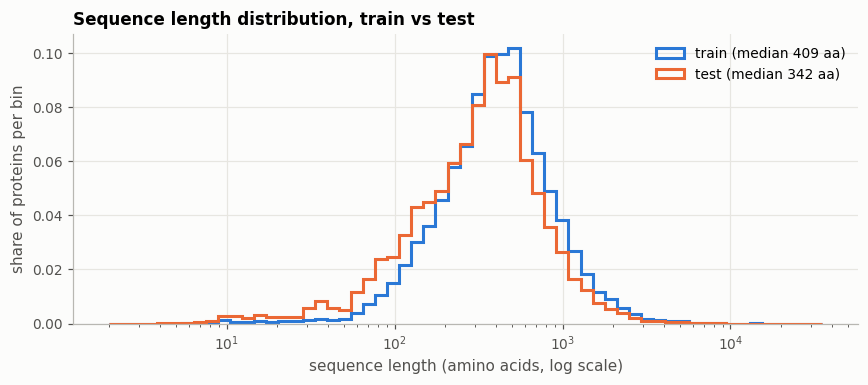

IQR rule: lengths above 1200 aa are outliers -> 6.3% of train proteins
train proteins longer than  512 aa:  35.9%
train proteins longer than 1024 aa:   9.3%
train proteins longer than 2048 aa:   1.5%


,EntryID,taxonomyID,length
31435,A2ASS6,10090,35213
7735,Q8WZ42,9606,34350
31622,G4SLH0,6239,18562
30582,Q9I7U4,7227,18141
1916,Q8WXI7,9606,14507


In [42]:
all_lengths = pd.concat([train_seq["length"], test_seq["length"]])
bins = np.logspace(np.log10(max(all_lengths.min(), 1)), np.log10(all_lengths.max() + 1), 60)

fig, ax = plt.subplots(figsize=(8, 3.6))
for split, frame in [("train", train_seq), ("test", test_seq)]:
    ax.hist(frame["length"], bins=bins, weights=np.full(len(frame), 1 / len(frame)), histtype="step",
            linewidth=2, color=SPLIT_COLORS[split],
            label=f"{split} (median {int(frame['length'].median())} aa)")
ax.set_xscale("log")
ax.set_xlabel("sequence length (amino acids, log scale)")
ax.set_ylabel("share of proteins per bin")
ax.set_title("Sequence length distribution, train vs test")
ax.legend()
plt.tight_layout()
plt.show()

q1, q3 = train_seq["length"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print(f"IQR rule: lengths above {upper_fence:.0f} aa are outliers -> {(train_seq['length'] > upper_fence).mean():.1%} of train proteins")
for limit in (512, 1024, 2048):
    print(f"train proteins longer than {limit:>4} aa: {(train_seq['length'] > limit).mean():6.1%}")
display(train_seq.nlargest(5, "length")[["EntryID", "taxonomyID", "length"]])

**Interpretation**
- **Shape.** The distribution is strongly right-skewed: the median is 409 aa and half of the proteins lie between 250 and 630 aa, but the mean is 526 aa and the range goes from 3 to 35,213 aa. On the log axis it looks roughly bell-shaped, which is why a log scale is used.
- **Outliers.** The IQR rule flags lengths above 1,200 aa, which is 6.3% of the training proteins. These are real proteins (the two longest, about 35,000 aa, are the mouse and human titin entries), not errors, so we keep them.
- **Train vs test.** Test proteins are shorter (median 342 aa vs 409 aa) and the test set has clearly more very short sequences below 100 aa. This is a mild distribution shift; scaling the feature vectors to unit length (section 4) reduces its effect.
- **Truncation.** 35.9% of the training proteins are longer than 512 aa, 9.3% longer than 1,024 aa and 1.5% longer than 2,048 aa. A language model with a 1,024-residue limit would truncate about one protein in eleven.

### 3.2 Amino-acid composition

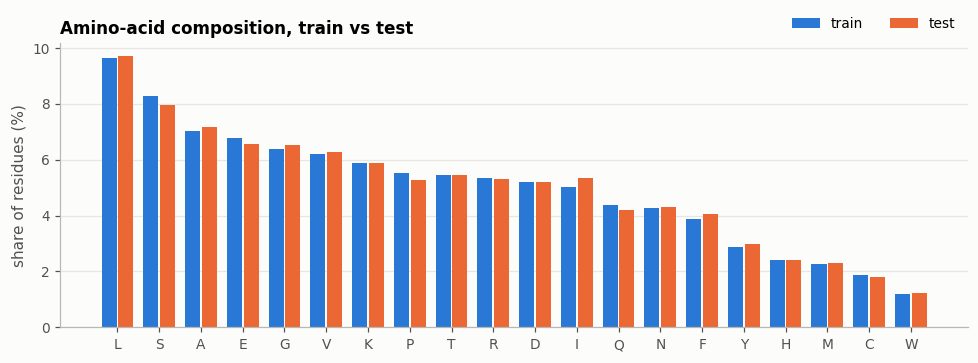

non-standard residues: train 0.0016%, test 0.0080%
largest train/test difference for one residue: 0.345% points


In [43]:
composition = pd.DataFrame({
    "train": amino_acid_composition(train_seq["sequence"]),
    "test": amino_acid_composition(test_seq["sequence"]),
})
order = composition.drop(index="other").sort_values("train", ascending=False).index

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(order))
for offset, split in [(-0.2, "train"), (0.2, "test")]:
    ax.bar(x + offset, composition.loc[order, split] * 100, width=0.36, color=SPLIT_COLORS[split], label=split)
ax.set_xticks(x)
ax.set_xticklabels(order)
ax.set_ylabel("share of residues (%)")
ax.set_title("Amino-acid composition, train vs test")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
plt.tight_layout()
plt.show()

print(f"non-standard residues: train {composition.loc['other', 'train']:.4%}, test {composition.loc['other', 'test']:.4%}")
print(f"largest train/test difference for one residue: {(composition['train'] - composition['test']).abs().max():.3%} points")

**Interpretation**
- Leucine (L) is the most common residue (about 9.6%), followed by serine (8.3%), alanine (7.0%) and glutamate (6.8%). Tryptophan (W, 1.2%) and cysteine (C, 1.9%) are the rarest.
- Train and test are practically identical: the largest difference for a single residue is 0.35 percentage points. At the level of residue composition there is no distribution shift, so k-mer features learned on the training set transfer to the test set.
- Non-standard residues are negligible (0.0016% of training residues, 0.0080% of test residues), so they need no special treatment.

### 3.3 Species (taxonomy)

Function annotation effort is concentrated on a few model organisms. If the species mix of the test set differs from training, validation scores can be too optimistic.

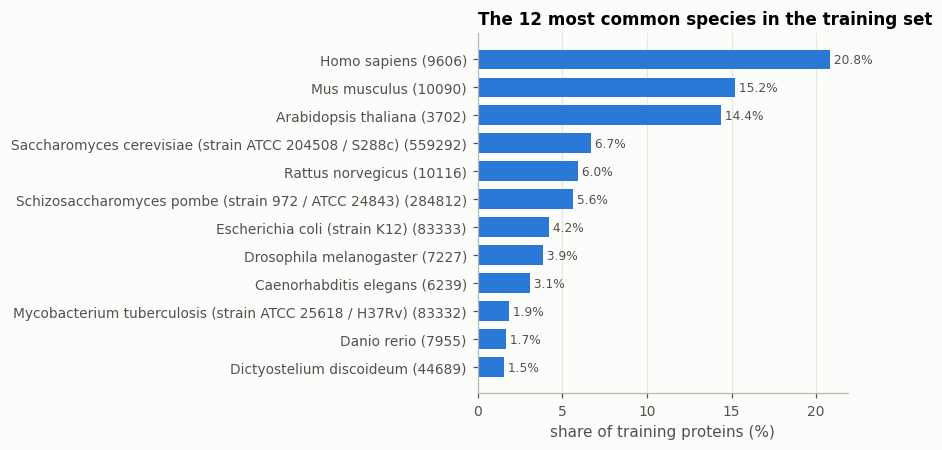

,species,train share,test share
taxonomyID,,,
9606,Homo sapiens,0.208,0.091
10090,Mus musculus,0.152,0.077
3702,Arabidopsis thaliana,0.144,0.073
559292,Saccharomyces cerevisiae (strain ATCC 204508 / S288c),0.067,0.030
10116,Rattus norvegicus,0.060,0.037
284812,Schizosaccharomyces pombe (strain 972 / ATCC 24843),0.056,0.023
83333,Escherichia coli (strain K12),0.042,0.020
7227,Drosophila melanogaster,0.039,0.017
6239,Caenorhabditis elegans,0.031,0.020


species in train: 1,381; species needed to cover 80% of training proteins: 10
test proteins whose species never appears in train: 17.2%


In [44]:
species_name = dict(zip(test_taxa["taxonomyID"], test_taxa["species"]))
train_taxon_share = train_tax["taxonomyID"].value_counts(normalize=True)
test_taxon_share = test_seq["taxonomyID"].dropna().astype(int).value_counts(normalize=True)

top_taxa = train_taxon_share.head(12)
labels = [f"{species_name.get(t, 'taxon')} ({t})" for t in top_taxa.index]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(np.arange(len(top_taxa))[::-1], top_taxa.to_numpy() * 100, height=0.7, color=SPLIT_COLORS["train"])
ax.set_yticks(np.arange(len(top_taxa))[::-1])
ax.set_yticklabels(labels)
for y, value in zip(np.arange(len(top_taxa))[::-1], top_taxa.to_numpy() * 100):
    ax.text(value, y, f" {value:.1f}%", va="center", fontsize=8, color=NEUTRAL)
ax.set_xlabel("share of training proteins (%)")
ax.set_title(f"The {len(top_taxa)} most common species in the training set")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

taxon_table = pd.DataFrame({"train share": train_taxon_share, "test share": test_taxon_share}).fillna(0.0)
taxon_table.insert(0, "species", [species_name.get(t, "") for t in taxon_table.index])
display(taxon_table.sort_values("train share", ascending=False).head(12))

cumulative = train_taxon_share.cumsum().to_numpy()
print(f"species in train: {len(train_taxon_share):,}; species needed to cover 80% of training proteins: {int(np.searchsorted(cumulative, 0.8) + 1)}")
train_taxa_set = set(train_taxon_share.index)
print(f"test proteins whose species never appears in train: {(~test_seq['taxonomyID'].dropna().astype(int).isin(train_taxa_set)).mean():.1%}")

**Interpretation**
- **Concentration.** The training data is dominated by model organisms: human (20.8%), mouse (15.2%) and *Arabidopsis thaliana* (14.4%) together make up half of it, and only 10 of the 1,381 species cover 80% of the proteins.
- **Test set.** The same three species lead the test set, but with much smaller shares (9.1%, 7.7%, 7.3%). The test set contains 8,453 species, and 17.2% of its proteins come from species that never appear in training.
- **Consequence.** A validation split taken from the training data over-represents well-studied organisms, so validation scores will be optimistic for the real test set. Any species feature must also work for species the model has never seen.

### 3.4 Target: the three aspects

,annotation_rows,distinct_terms,proteins,share of proteins,rows per protein
aspect,,,,,
BPO,250805,16858,59958,0.728,4.183
CCO,157770,2651,60292,0.732,2.617
MFO,128452,6616,58001,0.704,2.215


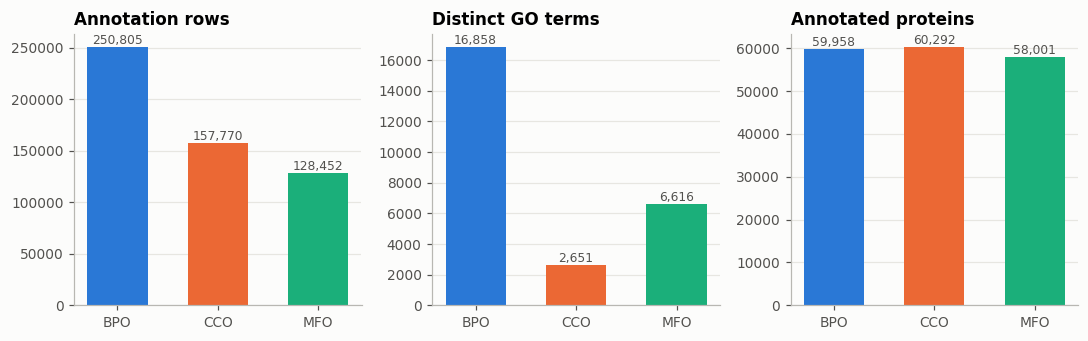

,proteins,share
aspect,,
BPO+CCO+MFO,36775,0.446
CCO,9934,0.121
BPO+MFO,8714,0.106
BPO+CCO,7341,0.089
BPO,7128,0.087
MFO,6270,0.076
CCO+MFO,6242,0.076


In [45]:
aspect_summary = train_terms.groupby("aspect").agg(
    annotation_rows=("term", "size"),
    distinct_terms=("term", "nunique"),
    proteins=("EntryID", "nunique"),
).reindex(ASPECTS)
aspect_summary["share of proteins"] = aspect_summary["proteins"] / train_terms["EntryID"].nunique()
aspect_summary["rows per protein"] = aspect_summary["annotation_rows"] / aspect_summary["proteins"]
display(aspect_summary)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, column, title in zip(axes, ["annotation_rows", "distinct_terms", "proteins"],
                             ["Annotation rows", "Distinct GO terms", "Annotated proteins"]):
    ax.bar(ASPECTS, aspect_summary[column], width=0.6, color=[ASPECT_COLORS[a] for a in ASPECTS])
    for i, value in enumerate(aspect_summary[column]):
        ax.text(i, value, format_count(value), ha="center", va="bottom", fontsize=8, color=NEUTRAL)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# which combinations of aspects does a protein have labels for?
combos = (train_terms.drop_duplicates(["EntryID", "aspect"]).sort_values("aspect")
          .groupby("EntryID")["aspect"].agg("+".join).value_counts())
display(pd.DataFrame({"proteins": combos, "share": combos / combos.sum()}))

**Interpretation**
- **Size per aspect.** BPO is by far the largest and most complex aspect: 250,805 annotation rows and 16,858 distinct terms (65% of the whole vocabulary). CCO has the smallest vocabulary (2,651 terms) although it has 157,770 rows; MFO lies in between (6,616 terms, 128,452 rows).
- **Coverage of proteins.** Each aspect is annotated for 70–73% of the proteins, but only 44.6% of the proteins have labels in all three aspects, and 28.3% have labels in just one.
- **Meaning of a missing aspect.** It means "not studied yet", not "no function". The official metric handles this by scoring each aspect only on proteins that have ground truth in it. Our baselines still train on these proteins with all-zero labels for the missing aspect, which is a simplification.
- **Expectation.** With the largest vocabulary and the most labels per protein, BPO should be the hardest aspect.

### 3.5 Target: number of GO terms per protein

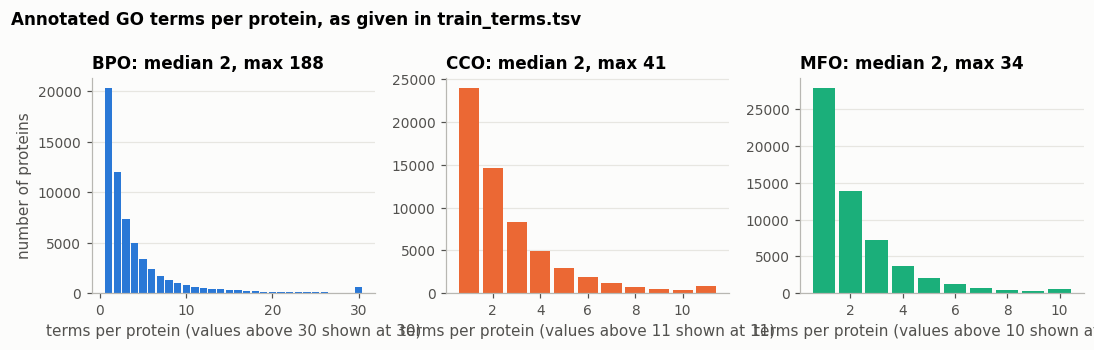

,count,mean,std,min,25%,50%,75%,max
aspect,,,,,,,,
BPO,"59,958.000",4.180,6.200,1.000,1.000,2.000,5.000,188.000
CCO,"60,292.000",2.620,2.280,1.000,1.000,2.000,3.000,41.000
MFO,"58,001.000",2.210,1.910,1.000,1.000,2.000,3.000,34.000


In [46]:
per_protein = train_terms.groupby(["aspect", "EntryID"]).size()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=False)
for ax, aspect in zip(axes, ASPECTS):
    counts = per_protein.loc[aspect]
    upper = int(max(counts.quantile(0.99), 5))
    ax.hist(counts.clip(upper=upper), bins=np.arange(0.5, upper + 1.5, 1), color=ASPECT_COLORS[aspect], rwidth=0.85)
    ax.set_title(f"{aspect}: median {counts.median():.0f}, max {counts.max()}")
    ax.set_xlabel(f"terms per protein (values above {upper} shown at {upper})")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of proteins")
fig.suptitle("Annotated GO terms per protein, as given in train_terms.tsv", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

display(per_protein.groupby("aspect").describe().reindex(ASPECTS).round(2))

**Interpretation**
- A typical protein has very few direct annotations: the median is 2 terms in every aspect, and the most common value is 1. The means are 4.2 (BPO), 2.6 (CCO) and 2.2 (MFO).
- The distributions have a heavy right tail, especially BPO, where one protein has 188 terms (41 in CCO, 34 in MFO). These heavily annotated proteins are intensively studied ones; they are outliers in the target but valid data, so we keep them.
- With about 6.5 terms per protein out of 26,125 possible ones, the label matrix is extremely sparse.

### 3.6 Target: the GO hierarchy and label propagation

A specific term implies all of its ancestors (*true path rule*), and the evaluation propagates labels this way. We first check whether `train_terms.tsv` already contains the ancestors, then add them.

annotations whose direct parents are all present: 3.7%
propagation took 4.5 s


,as given,after propagation
annotation rows,"537,027.000","3,564,990.000"
distinct terms,"26,125.000","29,386.000"
mean terms per protein,6.500,43.300
median terms per protein,4.000,31.000


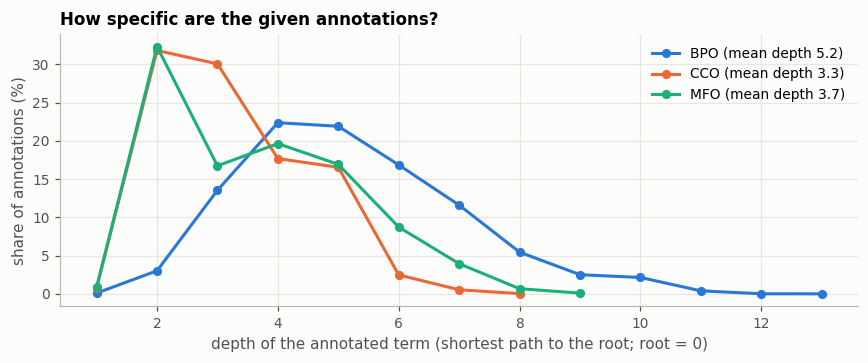

In [47]:
# For each annotation: are all direct parents of the term also annotated on that protein?
n_checked = n_complete = 0
for protein_terms in train_terms.groupby("EntryID")["term"].agg(set):
    canonical = {go.canonical(t) for t in protein_terms}
    for term in canonical:
        parents = go.parents.get(term, set())
        if parents:
            n_checked += 1
            n_complete += parents <= canonical
print(f"annotations whose direct parents are all present: {n_complete / max(n_checked, 1):.1%}")

start = time.time()
train_prop = propagate_annotations(train_terms, go)
print(f"propagation took {time.time() - start:.1f} s")

before = train_terms.groupby("EntryID")["term"].nunique()
after = train_prop.groupby("EntryID")["term"].nunique()
display(pd.DataFrame({
    "as given": [len(train_terms), train_terms["term"].nunique(), before.mean(), before.median()],
    "after propagation": [len(train_prop), train_prop["term"].nunique(), after.mean(), after.median()],
}, index=["annotation rows", "distinct terms", "mean terms per protein", "median terms per protein"]).round(1))

depth_of = {t: go.depth(t) for t in train_terms["term"].unique()}
depth_frame = train_terms.assign(depth=train_terms["term"].map(depth_of))

fig, ax = plt.subplots(figsize=(8, 3.4))
for aspect in ASPECTS:
    shares = depth_frame.loc[depth_frame["aspect"] == aspect, "depth"].value_counts(normalize=True).sort_index()
    ax.plot(shares.index, shares.to_numpy() * 100, marker="o", markersize=5, color=ASPECT_COLORS[aspect],
            label=f"{aspect} (mean depth {depth_frame.loc[depth_frame['aspect'] == aspect, 'depth'].mean():.1f})")
ax.set_xlabel("depth of the annotated term (shortest path to the root; root = 0)")
ax.set_ylabel("share of annotations (%)")
ax.set_title("How specific are the given annotations?")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation**
- **The file is not propagated.** Only 3.7% of the annotations have all of their direct parents listed for the same protein, so `train_terms.tsv` contains mostly the most specific terms.
- **Effect of propagation.** Adding all ancestors multiplies the rows by 6.6 (537,027 → 3,564,990). The mean number of terms per protein rises from 6.5 to 43.3 (median 4 → 31), and the vocabulary grows from 26,125 to 29,386 terms, because 3,261 ancestor terms are never annotated directly.
- **Depth.** CCO and MFO annotations are shallow (most at depth 2–3, mean depth 3.3 and 3.7). BPO annotations are deeper (most at depth 4–5, mean 5.2, with a tail up to depth 13), i.e. more specific, which again suggests BPO is the hardest aspect.

From here on we use the **propagated** labels (`train_prop`), because that is what the evaluation uses.

### 3.7 Target balance: a very long tail

In a multi-label problem "class balance" means: how many proteins does each GO term have?

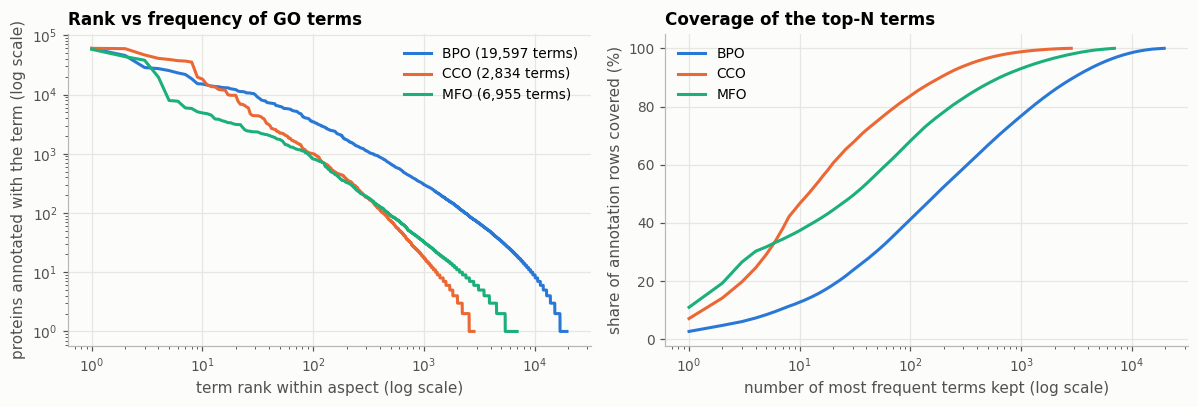

,terms,median_proteins,terms_under_10,terms_under_50,share under 10
aspect,,,,,
BPO,19597,9.000,9971,15678,0.509
CCO,2834,8.000,1513,2223,0.534
MFO,6955,5.000,4729,6211,0.680


,aspect,term,name,proteins,share of proteins,IA
0,BPO,GO:0008150,biological_process,59958,0.728,0.000
1,BPO,GO:0009987,cellular process,45634,0.554,0.394
2,BPO,GO:0065007,biological regulation,28599,0.347,1.068
3,BPO,GO:0050789,regulation of biological process,27388,0.332,0.062
4,BPO,GO:0050794,regulation of cellular process,25363,0.308,0.111
5,BPO,GO:0008152,metabolic process,23166,0.281,0.978
6,BPO,GO:0050896,response to stimulus,21841,0.265,1.457
7,BPO,GO:0044238,primary metabolic process,18448,0.224,0.329
8,CCO,GO:0005575,cellular_component,60292,0.732,0.000
9,CCO,GO:0110165,cellular anatomical structure,59516,0.722,0.019


In [48]:
n_labelled = train_prop["EntryID"].nunique()
term_counts = train_prop.groupby(["aspect", "term"]).size().rename("proteins").reset_index()
term_counts = term_counts.sort_values(["aspect", "proteins"], ascending=[True, False])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for aspect in ASPECTS:
    counts = term_counts.loc[term_counts["aspect"] == aspect, "proteins"].to_numpy()
    rank = np.arange(1, len(counts) + 1)
    axes[0].plot(rank, counts, color=ASPECT_COLORS[aspect], label=f"{aspect} ({len(counts):,} terms)")
    axes[1].plot(rank, np.cumsum(counts) / counts.sum() * 100, color=ASPECT_COLORS[aspect], label=aspect)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("term rank within aspect (log scale)")
axes[0].set_ylabel("proteins annotated with the term (log scale)")
axes[0].set_title("Rank vs frequency of GO terms")
axes[0].legend()
axes[1].set_xscale("log")
axes[1].set_xlabel("number of most frequent terms kept (log scale)")
axes[1].set_ylabel("share of annotation rows covered (%)")
axes[1].set_title("Coverage of the top-N terms")
axes[1].legend()
plt.tight_layout()
plt.show()

tail = term_counts.groupby("aspect")["proteins"].agg(
    terms="size",
    median_proteins="median",
    terms_under_10=lambda s: (s < 10).sum(),
    terms_under_50=lambda s: (s < 50).sum(),
).reindex(ASPECTS)
tail["share under 10"] = tail["terms_under_10"] / tail["terms"]
display(tail)

top_terms = term_counts.groupby("aspect").head(8).copy()
top_terms["name"] = top_terms["term"].map(go.name)
top_terms["share of proteins"] = top_terms["proteins"] / n_labelled
top_terms["IA"] = top_terms["term"].map(ia)
display(top_terms[["aspect", "term", "name", "proteins", "share of proteins", "IA"]].reset_index(drop=True))

**Interpretation**
- **Extreme imbalance.** After propagation the median term has only 9 (BPO), 8 (CCO) and 5 (MFO) training proteins. 51%, 53% and 68% of the terms have fewer than 10 proteins, and 80%, 78% and 89% have fewer than 50. Most labels are too rare to learn with a standard classifier.
- **Head of the distribution.** At the other end, generic terms near the roots are attached to a large share of the proteins: *cellular process* 55.4%, *cellular anatomical structure* 72.2%, *binding* 53.0%, *protein binding* 46.1%.
- **Coverage.** A small number of terms covers most annotation rows, but the aspects differ: roughly 100 CCO terms or 300 MFO terms cover about 80% of the rows, while BPO needs more than 1,000 terms for the same coverage.
- **IA of the frequent terms.** The most frequent terms have very low IA (0 to about 1.6), so predicting them correctly earns little (section 3.8).
- **Decision.** For the baselines we predict only the most frequent terms of each aspect (section 4).

### 3.8 Information accretion (IA) weights

The metric weights every term by its IA (section 1.3), so it matters how IA relates to term frequency.

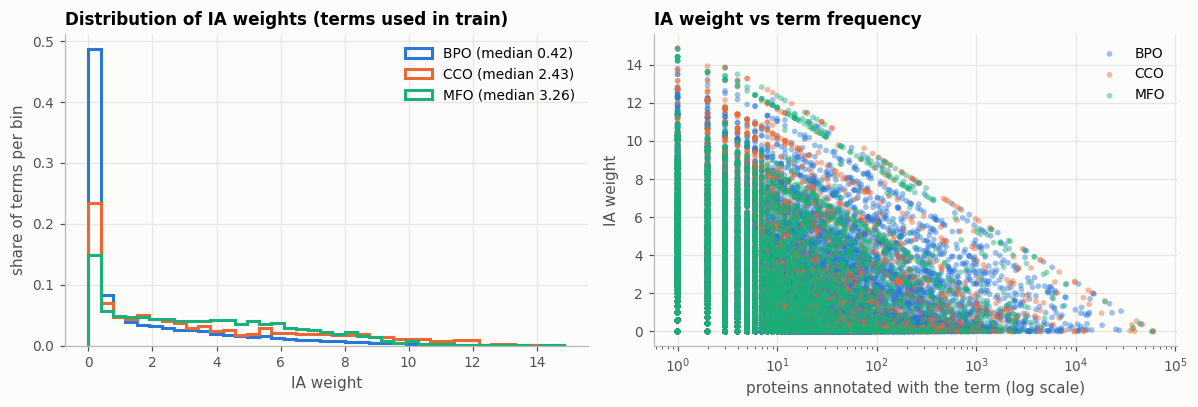

terms with IA = 0: 24.9% of the terms used in train
Spearman correlation between term frequency and IA: -0.1
IA of the three root terms: {'BPO': 0.0, 'CCO': 0.0, 'MFO': 0.0}


In [49]:
ia_frame = term_counts.assign(IA=term_counts["term"].map(ia).fillna(0.0))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ia_bins = np.linspace(0, max(ia_frame["IA"].max(), 1e-9), 40)
for aspect in ASPECTS:
    subset = ia_frame[ia_frame["aspect"] == aspect]
    axes[0].hist(subset["IA"], bins=ia_bins, histtype="step", linewidth=2, color=ASPECT_COLORS[aspect],
                 weights=np.full(len(subset), 1 / max(len(subset), 1)),
                 label=f"{aspect} (median {subset['IA'].median():.2f})")
    axes[1].scatter(subset["proteins"], subset["IA"], s=14, alpha=0.45, color=ASPECT_COLORS[aspect],
                    edgecolors="none", label=aspect)
axes[0].set_xlabel("IA weight")
axes[0].set_ylabel("share of terms per bin")
axes[0].set_title("Distribution of IA weights (terms used in train)")
axes[0].legend()
axes[1].set_xscale("log")
axes[1].set_xlabel("proteins annotated with the term (log scale)")
axes[1].set_ylabel("IA weight")
axes[1].set_title("IA weight vs term frequency")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"terms with IA = 0: {(ia_frame['IA'] == 0).mean():.1%} of the terms used in train")
print("Spearman correlation between term frequency and IA:",
      round(ia_frame[["proteins", "IA"]].corr(method="spearman").iloc[0, 1], 3))
print("IA of the three root terms:", {a: float(ia.get(t, np.nan)) for a, t in ROOT_TERMS.items()})

**Interpretation**
- **Distribution.** 24.9% of the terms used in training have IA = 0: they are fully implied by their parents. The rest is spread over a long tail up to about 15. The median IA is much lower in BPO (0.42) than in CCO (2.43) and MFO (3.26), so BPO contains many low-information terms.
- **Relation to frequency.** Over all terms the rank correlation is weak (Spearman −0.10), but the scatter plot shows a clear upper limit: the maximum IA falls as frequency rises. Terms with more than 10,000 proteins all have IA below about 2, while rare terms range from 0 up to 15. Frequent terms are always low-weight; rare terms may or may not be high-weight.
- **Why this makes the task hard.** The terms that are easiest to predict (frequent, generic) contribute almost nothing to the score, and the three root terms have IA = 0. The score is decided by specific terms that have few training examples.

### 3.9 Relationships between the inputs and the target

Do the two inputs we have, sequence length and species, tell us anything about the labels?

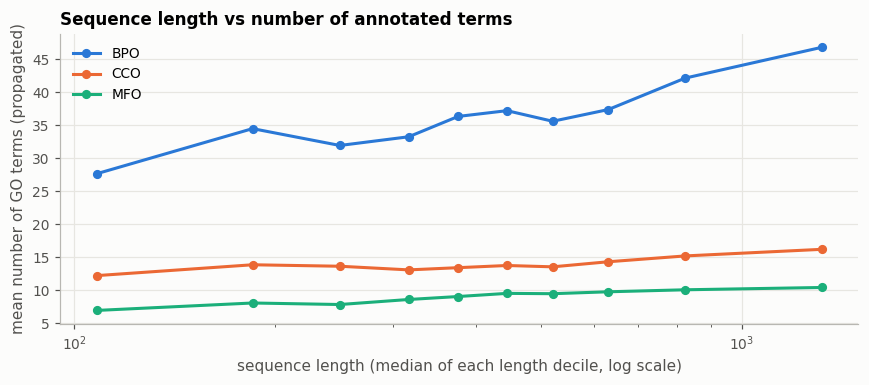

Spearman correlation between sequence length and number of terms: 0.19


In [50]:
terms_wide = train_prop.groupby(["EntryID", "aspect"]).size().unstack(fill_value=0).reindex(columns=ASPECTS, fill_value=0)
relation = train_seq.drop_duplicates("EntryID").set_index("EntryID")[["length"]].join(terms_wide, how="inner")
relation["all aspects"] = relation[ASPECTS].sum(axis=1)
relation["length_bin"] = pd.qcut(relation["length"], 10, duplicates="drop")
by_length = relation.groupby("length_bin", observed=True)

fig, ax = plt.subplots(figsize=(8, 3.6))
for aspect in ASPECTS:
    # mean over the proteins that are annotated in this aspect
    means = by_length[aspect].apply(lambda s: s[s > 0].mean())
    ax.plot(by_length["length"].median().to_numpy(), means.to_numpy(), marker="o", markersize=5,
            color=ASPECT_COLORS[aspect], label=aspect)
ax.set_xscale("log")
ax.set_xlabel("sequence length (median of each length decile, log scale)")
ax.set_ylabel("mean number of GO terms (propagated)")
ax.set_title("Sequence length vs number of annotated terms")
ax.legend()
plt.tight_layout()
plt.show()

print("Spearman correlation between sequence length and number of terms:",
      round(relation[["length", "all aspects"]].corr(method="spearman").iloc[0, 1], 3))

**Interpretation**
- There is a weak positive relationship (Spearman 0.19). In BPO the mean number of propagated terms rises from about 28 in the shortest length decile (around 110 aa) to about 47 in the longest (around 1,300 aa); in CCO from 12 to 16 and in MFO from 7 to 10.5.
- This is plausible: longer proteins tend to have more domains and therefore more functions.
- Length alone is a weak predictor. It can say a little about *how many* terms a protein has, but nothing about *which* ones, so the model needs the content of the sequence.

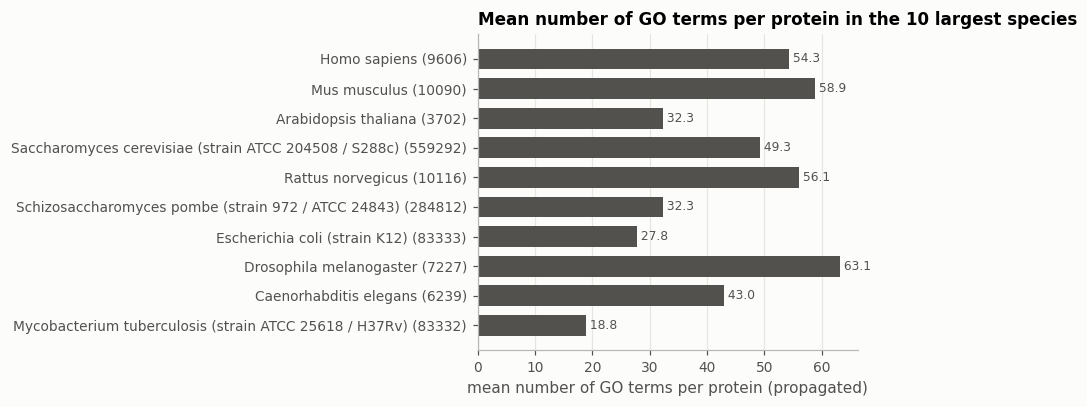

,proteins,mean_terms,share with all three aspects
taxonomyID,,,
9606,17162,54.338,0.633
10090,12508,58.866,0.491
3702,11863,32.272,0.365
559292,5520,49.295,0.743
10116,4909,56.064,0.460
284812,4636,32.266,0.334
83333,3466,27.812,0.439
7227,3201,63.141,0.560
6239,2540,42.964,0.379


In [51]:
by_species = relation.join(train_tax.drop_duplicates("EntryID").set_index("EntryID")["taxonomyID"], how="inner")
grouped = by_species.groupby("taxonomyID")
species_stats = pd.DataFrame({
    "proteins": grouped.size(),
    "mean_terms": grouped["all aspects"].mean(),
    "share with all three aspects": (by_species[ASPECTS] > 0).all(axis=1).groupby(by_species["taxonomyID"]).mean(),
}).sort_values("proteins", ascending=False).head(10)
species_labels = [f"{species_name.get(t, 'taxon')} ({t})" for t in species_stats.index]

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(species_stats))[::-1]
ax.barh(y, species_stats["mean_terms"], height=0.7, color=NEUTRAL)
for yi, value in zip(y, species_stats["mean_terms"]):
    ax.text(value, yi, f" {value:.1f}", va="center", fontsize=8, color=NEUTRAL)
ax.set_yticks(y)
ax.set_yticklabels(species_labels)
ax.set_xlabel("mean number of GO terms per protein (propagated)")
ax.set_title(f"Mean number of GO terms per protein in the {len(species_stats)} largest species")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
display(species_stats)

**Interpretation**
- **Annotation depth differs strongly between species.** Fruit fly (63.1), mouse (58.9), rat (56.1) and human (54.3) have the most terms per protein; *Arabidopsis* (32.3), fission yeast (32.3), *E. coli* (27.8) and *M. tuberculosis* (18.8) have far fewer. The share of proteins with all three aspects ranges from 74.3% in baker's yeast and 63.3% in human down to 22.0% in *M. tuberculosis*.
- **Reading.** These differences mostly reflect how intensively a species has been studied and which kinds of processes are annotated in it, not that bacterial proteins "do less". Labels of less-studied species are more incomplete.
- **Consequence.** Species carries information about how many and which terms to expect, so it is a candidate feature for Assignment 2. Because 17.2% of the test proteins come from unseen species, it would have to be used at a coarse level (for example kingdom) rather than as an exact species id.

### 3.10 EDA summary

- **Size and type.** 82,404 training proteins, 537,027 annotations, 26,125 distinct GO terms: a multi-label problem with a very large label space. The test superset has 224,309 proteins and includes all training proteins.
- **Clean data.** No missing values and no duplicate ids; 1.5% duplicate sequences and 0.24% sequences with non-standard residues. No imputation or removal is needed.
- **Incomplete labels.** Only 44.6% of the proteins are annotated in all three aspects. A missing aspect means "unknown".
- **Hierarchy.** The given labels are not propagated (3.7%). After propagation a protein has 43 terms on average instead of 6.5, so labels must be propagated before training and predictions should respect the hierarchy.
- **Long tail.** More than half of the terms have fewer than 10 proteins, so we restrict the label space to the most frequent terms.
- **Metric.** IA weights give frequent generic terms almost no value (a quarter of the terms weigh 0), so good scores require predicting specific terms.
- **Aspects.** BPO has the largest vocabulary, the deepest terms and the lowest median IA; we expect it to be the hardest.
- **Train vs test.** Residue composition is identical, but test proteins are shorter (median 342 vs 409 aa) and come from many more species (17.2% from unseen species), so validation on a random split of the training data will be optimistic.

## 4. Preprocessing

Each step below is motivated by a finding from sections 2–3.

| Step | What we do | Why |
|---|---|---|
| Cleaning | keep one row per protein id; keep proteins that have both a sequence and labels | there are no duplicate ids and every protein has a sequence and labels (section 2.4), so all 82,404 proteins are kept; the checks stay in the code as a safeguard |
| Duplicate sequences | kept | only 1,221 sequences (1.5%) are duplicates and they carry valid labels; the small leakage they cause in a random split is noted as a limitation |
| Non-standard residues | kept as they are | only 200 sequences (0.24%) contain them; they simply form their own rare 3-mers |
| Outliers | very long proteins and heavily annotated proteins are kept | the 6.3% of proteins above 1,200 aa and the proteins with up to 188 terms are real biology, not measurement errors (sections 3.1, 3.5) |
| Missing values / imputation | nothing is imputed | no table has a missing cell (section 2.3); a missing aspect means "unknown", so inventing labels would be wrong |
| Target encoding | propagate labels up the GO graph, then encode as a sparse multi-hot matrix | only 3.7% of the given annotations are propagated but the evaluation uses propagated labels (section 3.6); with 29,386 terms and 0.147% non-zero cells a sparse format is necessary |
| Label space | predict only the 600 / 200 / 300 most frequent BPO / CCO / MFO terms | more than half of the terms have fewer than 10 proteins (section 3.7); recall is still measured against all true terms |
| Split | 20% held-out validation with `random_state=42` (65,923 train, 16,481 validation) | test labels are not public; stratification is not possible because every protein has many labels |
| Feature encoding | overlapping 3-mers, TF-IDF weighted (8,130 features) | turns variable-length strings into fixed-length numeric vectors |
| Scaling | sublinear term frequency and L2 normalisation of every vector | lengths range from 3 to 35,213 aa (section 3.1); without scaling, long proteins would dominate |

The featuriser is **fitted on the training split only**, to avoid leaking validation information.

In [52]:
# ---- configuration -------------------------------------------------------
LABELS_PER_ASPECT = {"BPO": 600, "CCO": 200, "MFO": 300}   # most frequent terms kept per aspect
VAL_FRACTION = 0.2
KMER_K = 3
KNN_K = 10
MLP_HIDDEN = 512
MLP_EPOCHS = 15
MAX_PROTEINS = None   # e.g. 5000 for a quick debugging run; None = use everything
# --------------------------------------------------------------------------

# cleaning: one sequence per id, only proteins that have a sequence and at least one label
sequences = train_seq.drop_duplicates("EntryID").set_index("EntryID")["sequence"]
sequences = sequences[sequences.str.len() > 0]
protein_ids = np.array(sorted(set(train_prop["EntryID"]) & set(sequences.index)))
print(f"proteins after cleaning: {len(protein_ids):,} (of {train_seq['EntryID'].nunique():,} in the FASTA file)")
if MAX_PROTEINS is not None and len(protein_ids) > MAX_PROTEINS:
    protein_ids = np.random.default_rng(SEED).choice(protein_ids, MAX_PROTEINS, replace=False)

# split
train_ids, val_ids = train_test_split(protein_ids, test_size=VAL_FRACTION, random_state=SEED)
print(f"train proteins: {len(train_ids):,}   validation proteins: {len(val_ids):,}")

# target encoding: sparse multi-hot matrices over every term seen in training
all_terms = sorted(train_prop["term"].unique())
term_aspect = dict(zip(train_prop["term"], train_prop["aspect"]))
Y_train_all = build_label_matrix(train_prop, train_ids, all_terms)
Y_val_all = build_label_matrix(train_prop, val_ids, all_terms)
print(f"label matrix (train): {Y_train_all.shape[0]:,} x {Y_train_all.shape[1]:,}, "
      f"{Y_train_all.nnz / (Y_train_all.shape[0] * Y_train_all.shape[1]):.3%} of the cells are 1")

proteins after cleaning: 82,404 (of 82,404 in the FASTA file)
train proteins: 65,923   validation proteins: 16,481
label matrix (train): 65,923 x 29,386, 0.147% of the cells are 1


In [53]:
# label space: the most frequent terms of each aspect, counted on the training split only
train_counts = np.asarray(Y_train_all.sum(axis=0)).ravel()
all_aspects = np.array([term_aspect[t] for t in all_terms])

label_cols = []
for aspect in ASPECTS:
    cols = np.where((all_aspects == aspect) & (train_counts > 0))[0]
    label_cols.extend(cols[np.argsort(-train_counts[cols], kind="stable")][: LABELS_PER_ASPECT[aspect]])
label_cols = np.array(label_cols)
label_terms = [all_terms[j] for j in label_cols]
label_aspects = all_aspects[label_cols]

Y_train = Y_train_all[:, label_cols]
Y_val = Y_val_all[:, label_cols]

ia_all = ia.reindex(all_terms).fillna(0.0).to_numpy()
val_counts = np.asarray(Y_val_all.sum(axis=0)).ravel()
in_labels = np.zeros(len(all_terms), dtype=bool)
in_labels[label_cols] = True
coverage = []
for aspect in ASPECTS:
    mask = all_aspects == aspect
    coverage.append({
        "aspect": aspect,
        "terms in train": int(mask.sum()),
        "terms we predict": int((mask & in_labels).sum()),
        "least frequent kept term (train proteins)": int(train_counts[mask & in_labels].min()),
        "validation annotations covered": val_counts[mask & in_labels].sum() / max(val_counts[mask].sum(), 1),
        "IA-weighted coverage": (val_counts * ia_all)[mask & in_labels].sum() / max((val_counts * ia_all)[mask].sum(), 1e-12),
    })
display(pd.DataFrame(coverage).set_index("aspect"))

,terms in train,terms we predict,least frequent kept term (train proteins),validation annotations covered,IA-weighted coverage
aspect,,,,,
BPO,19597,600,444,0.691,0.608
CCO,2834,200,303,0.906,0.788
MFO,6955,300,154,0.829,0.682


The table shows the price of truncating the label space. We keep 1,100 of the 29,386 terms (3.7%). They cover 69.1% (BPO), 90.6% (CCO) and 82.9% (MFO) of the validation annotation rows, but only 60.8%, 78.8% and 68.2% once every term is weighted by its IA, because the rare terms we dropped are the ones with high weight. Even the least frequent kept term still has 444 (BPO), 303 (CCO) and 154 (MFO) training proteins, so every kept label has enough examples.

For a baseline this trade-off is acceptable, but it puts a ceiling on the recall we can reach, especially in BPO. The ceiling is quantified as the "upper bound" in section 5.1.

In [54]:
# feature encoding and scaling: k-mer TF-IDF, fitted on the training split only
start = time.time()
featurizer = KmerFeaturizer(k=KMER_K)
X_train = featurizer.fit_transform(sequences.loc[train_ids])
X_val = featurizer.transform(sequences.loc[val_ids])
row_norms = np.sqrt(np.asarray(X_train.multiply(X_train).sum(axis=1)).ravel())
print(f"k-mer TF-IDF features: {X_train.shape[1]:,} columns, "
      f"{X_train.nnz / X_train.shape[0]:.0f} non-zeros per protein on average ({time.time() - start:.1f} s)")
print(f"L2 norm of the feature vectors: min {row_norms.min():.3f}, max {row_norms.max():.3f} (all scaled to length 1)")

k-mer TF-IDF features: 8,130 columns, 458 non-zeros per protein on average (28.7 s)
L2 norm of the feature vectors: min 1.000, max 1.000 (all scaled to length 1)


## 5. Baseline models

All models are trained on the training split and scored on the validation split with the competition metric (section 1.3).

| Baseline | Uses the sequence? | Idea |
|---|---|---|
| Naive | no | every protein gets the same scores: the training frequency of each term |
| k-NN on k-mers | yes | copy labels from the most similar training sequences (homology transfer) |
| MLP on k-mers | yes | one-hidden-layer neural network, one sigmoid output per term |

For the MLP we also report the scores after **hierarchy propagation** (a parent gets at least the score of its highest-scoring child). The naive and k-NN scores respect the hierarchy by construction.

### 5.1 Evaluation function and sanity checks

Predicting the exact truth for every kept term gives the **upper bound** our label space allows; random scores show the floor.

In [55]:
results, curves = [], {}


def evaluate(name, scores, keep=True):
    res = evaluate_predictions(Y_val_all, all_terms, scores, label_terms, ia, term_aspect)
    if keep:
        results.append(results_row(name, res))
        curves[name] = res
    print(f"{name:<42} " + "  ".join(f"{a} {res[a]['fmax']:.4f}" for a in ASPECTS) + f"   mean {res['mean_fmax']:.4f}")
    return res


oracle = evaluate("Upper bound (perfect on kept terms)", Y_val.toarray(), keep=False)
random_scores = np.random.default_rng(SEED).random(Y_val.shape, dtype=np.float32)
_ = evaluate("Random scores", random_scores, keep=False)

Upper bound (perfect on kept terms)        BPO 0.7997  CCO 0.9352  MFO 0.8829   mean 0.8726
Random scores                              BPO 0.0655  CCO 0.0700  MFO 0.0330   mean 0.0562


### 5.2 Naive baseline (term frequency)

In [56]:
naive = NaiveFrequencyBaseline(label_aspects).fit(X_train, Y_train)
scores_naive = naive.predict(X_val)
_ = evaluate("Naive (term frequency)", scores_naive)

Naive (term frequency)                     BPO 0.2238  CCO 0.3588  MFO 0.3644   mean 0.3157


### 5.3 k-nearest neighbours on k-mer TF-IDF

In [57]:
start = time.time()
knn = KNNBaseline(k=KNN_K).fit(X_train, Y_train)
scores_knn = knn.predict(X_val)
print(f"k-NN prediction took {time.time() - start:.1f} s")
_ = evaluate(f"k-NN (k={KNN_K})", scores_knn)

# k-NN averages labels that are already propagated, so its scores respect the hierarchy by construction:
change = np.abs(propagate_scores(scores_knn, label_terms, go) - scores_knn).max()
print(f"largest score change if we propagate the k-NN scores: {change:.2e}")

k-NN prediction took 196.0 s
k-NN (k=10)                                BPO 0.2687  CCO 0.4160  MFO 0.4298   mean 0.3715
largest score change if we propagate the k-NN scores: 0.00e+00


### 5.4 MLP on k-mer TF-IDF

MLP training took 795.8 s
MLP                                        BPO 0.2884  CCO 0.4786  MFO 0.4844   mean 0.4171
MLP + propagation                          BPO 0.2916  CCO 0.4824  MFO 0.4902   mean 0.4214


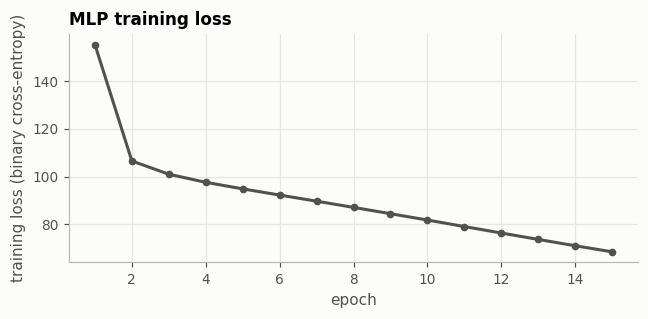

In [58]:
start = time.time()
mlp = MLPBaseline(hidden_units=MLP_HIDDEN, epochs=MLP_EPOCHS, random_state=SEED).fit(X_train, Y_train)
print(f"MLP training took {time.time() - start:.1f} s")
scores_mlp = mlp.predict(X_val)
_ = evaluate("MLP", scores_mlp)
scores_mlp_prop = propagate_scores(scores_mlp, label_terms, go)
_ = evaluate("MLP + propagation", scores_mlp_prop)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(mlp.loss_curve) + 1), mlp.loss_curve, color=NEUTRAL, marker="o", markersize=4)
ax.set_xlabel("epoch")
ax.set_ylabel("training loss (binary cross-entropy)")
ax.set_title("MLP training loss")
plt.tight_layout()
plt.show()

**Interpretation**
- The training loss falls sharply after the first epoch (155 → 107) and then keeps decreasing steadily to 68 at epoch 15 without flattening, so the network has not converged yet.
- More epochs would probably fit the training data better, but the training loss alone cannot tell us when overfitting starts. In Assignment 2 we should monitor the validation score and stop early. Training already took 796 s on CPU.

### 5.5 Results on the validation split

,Fmax BPO,Fmax CCO,Fmax MFO,Fmax mean,thr BPO,thr CCO,thr MFO
model,,,,,,,
Naive (term frequency),0.224,0.359,0.364,0.316,0.120,0.200,0.350
k-NN (k=10),0.269,0.416,0.430,0.372,0.280,0.290,0.420
MLP,0.288,0.479,0.484,0.417,0.110,0.190,0.190
MLP + propagation,0.292,0.482,0.490,0.421,0.110,0.190,0.220


upper bound with this label space: mean F-max 0.8726


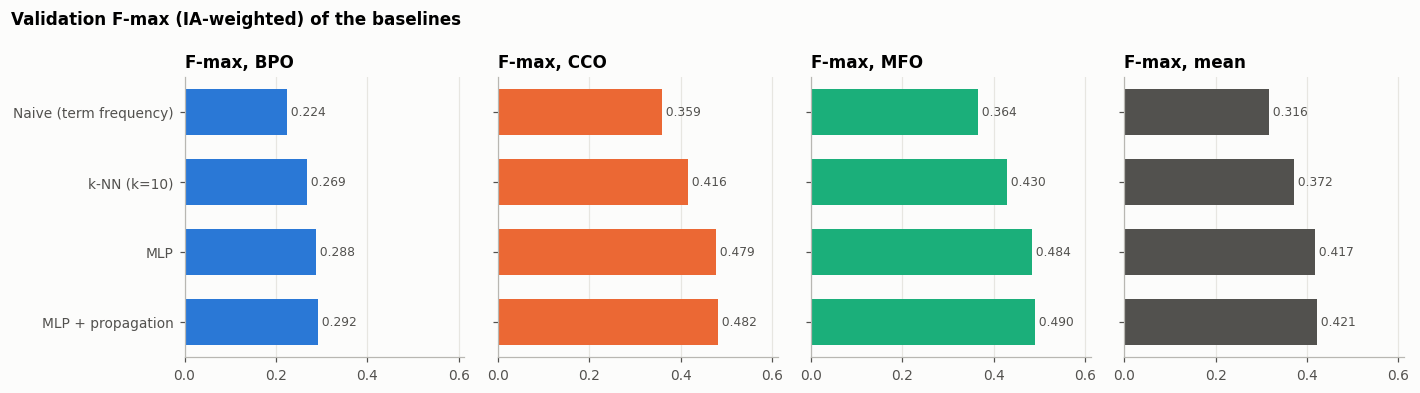

In [59]:
results_table = pd.DataFrame(results).set_index("model")
display(results_table)
print(f"upper bound with this label space: mean F-max {oracle['mean_fmax']:.4f}")

panels = [f"Fmax {a}" for a in ASPECTS] + ["Fmax mean"]
panel_colors = [ASPECT_COLORS[a] for a in ASPECTS] + [NEUTRAL]
fig, axes = plt.subplots(1, 4, figsize=(13, 0.5 * len(results_table) + 1.6), sharey=True)
y = np.arange(len(results_table))[::-1]
for ax, column, color in zip(axes, panels, panel_colors):
    ax.barh(y, results_table[column], height=0.65, color=color)
    for yi, value in zip(y, results_table[column]):
        ax.text(value, yi, f" {value:.3f}", va="center", fontsize=8, color=NEUTRAL)
    ax.set_title(column.replace("Fmax ", "F-max, "))
    ax.set_xlim(0, max(results_table[panels].to_numpy().max() * 1.25, 0.05))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y)
axes[0].set_yticklabels(results_table.index)
fig.suptitle("Validation F-max (IA-weighted) of the baselines", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation**
- **Ranking.** MLP + propagation (mean F-max 0.421) > MLP (0.417) > k-NN (0.372) > naive (0.316). For reference, random scores give 0.056 and the upper bound of our label space is 0.873.
- **The naive baseline is strong.** Without looking at the sequence it reaches 0.316, because a few generic terms are present in most proteins. This shows why a naive baseline is needed to judge the other models.
- **Gain from the sequence.** k-NN improves the mean F-max by 0.056 (+18%) and the MLP with propagation by 0.106 (+33%) over the naive baseline. The gain is largest in CCO (+0.124) and MFO (+0.126) and smallest in BPO (+0.068).
- **Propagation.** Making the MLP scores consistent with the hierarchy gives a small but consistent gain in every aspect (mean +0.004) at no cost.
- **Hardest aspect.** BPO (best F-max 0.292), as expected from the EDA: it has the largest vocabulary (19,597 propagated terms), the deepest terms and the lowest IA-weighted coverage of our label space (60.8%).
- **Thresholds.** The best thresholds of the MLP are low (0.11–0.22): the model gives small probabilities to specific terms, and F-max is reached by accepting many low-confidence predictions.

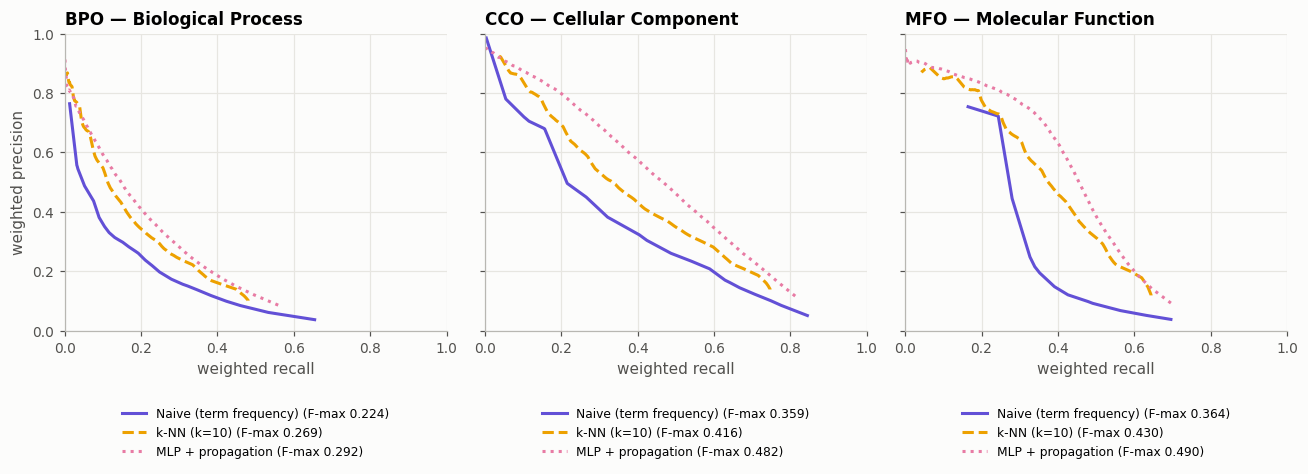

In [60]:
# precision-recall curves of the three model families (best variant of each)
def best_variant(prefix):
    names = [n for n in curves if n.startswith(prefix)]
    return max(names, key=lambda n: curves[n]["mean_fmax"])

shown = [best_variant("Naive"), best_variant("k-NN"), best_variant("MLP")]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, aspect in zip(axes, ASPECTS):
    for name, (color, style) in zip(shown, MODEL_STYLES):
        curve = curves[name][aspect]["curve"]
        curve = curve[(curve["precision"] > 0) | (curve["recall"] > 0)]
        ax.plot(curve["recall"], curve["precision"], color=color, linestyle=style,
                label=f"{name} (F-max {curves[name][aspect]['fmax']:.3f})")
    ax.set_title(f"{aspect} — {ASPECT_FULL_NAMES[aspect]}")
    ax.set_xlabel("weighted recall")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=8)
axes[0].set_ylabel("weighted precision")
plt.tight_layout()
plt.show()

**Interpretation**
- In CCO and MFO the MLP curve lies above the k-NN and naive curves over almost the whole recall range. In BPO the three curves are close together and precision drops below 0.5 at a recall of only about 0.15.
- The curves end at a recall of roughly 0.6 (BPO), 0.8 (CCO) and 0.7 (MFO). This is the maximum recall our label space allows, in line with its IA-weighted coverage (61%, 79%, 68%).
- The best baseline (0.421) reaches less than half of the upper bound (0.873). The main limits are: 3-mers ignore long-range order and structure; rare, high-IA terms are not predicted at all; proteins without labels in an aspect are treated as negatives during training; and the random split is optimistic, because identical or similar sequences can fall on both sides.

## 6. Kaggle submission

The competition expects a tab-separated file without header: `protein id`, `GO term`, `score` in (0, 1]. We use the best baseline on validation, propagate its scores and keep the highest scoring terms per protein. The file is large, so it is **not committed** (see `.gitignore`).

In [61]:
MAKE_SUBMISSION = True
SUBMISSION_PATH = Path("submission.tsv")
SUBMISSION_TOP_K = 40      # terms written per protein
SUBMISSION_MODEL = "MLP"    # None = best baseline on validation; or force "k-NN" / "MLP"
CHUNK = 5000               # note: k-NN compares every test protein with every training protein,
                           # so on the full test set it is much slower than the MLP

models = {"k-NN": knn, "MLP": mlp}
best_family = SUBMISSION_MODEL or max(models, key=lambda fam: curves[best_variant(fam)]["mean_fmax"])
print("model used for the submission:", best_variant(best_family))

if MAKE_SUBMISSION:
    start = time.time()
    targets = test_seq.drop_duplicates("EntryID")
    n_lines = 0
    for begin in range(0, len(targets), CHUNK):
        chunk = targets.iloc[begin:begin + CHUNK]
        scores = models[best_family].predict(featurizer.transform(chunk["sequence"]))
        scores = propagate_scores(scores, label_terms, go)
        n_lines += write_submission(SUBMISSION_PATH, chunk["EntryID"].to_numpy(), scores, label_terms,
                                    top_k=SUBMISSION_TOP_K, append=begin > 0)
        if (begin // CHUNK) % 5 == 0:
            print(f"  {min(begin + CHUNK, len(targets)):>7,} / {len(targets):,} proteins ({time.time() - start:.0f} s)")
    print(f"wrote {n_lines:,} lines for {len(targets):,} proteins to {SUBMISSION_PATH} "
          f"({SUBMISSION_PATH.stat().st_size / 1e6:.1f} MB, {time.time() - start:.0f} s)")
    display(pd.read_csv(SUBMISSION_PATH, sep="\t", header=None, names=["protein", "term", "score"], nrows=5))

model used for the submission: MLP + propagation
    5,000 / 224,309 proteins (3 s)
   30,000 / 224,309 proteins (22 s)
   55,000 / 224,309 proteins (39 s)
   80,000 / 224,309 proteins (54 s)
  105,000 / 224,309 proteins (68 s)
  130,000 / 224,309 proteins (82 s)
  155,000 / 224,309 proteins (96 s)
  180,000 / 224,309 proteins (109 s)
  205,000 / 224,309 proteins (120 s)
wrote 8,958,547 lines for 224,309 proteins to submission.tsv (215.7 MB, 129 s)


,protein,term,score
0,A0A087X1C5,GO:0003824,0.888
1,A0A087X1C5,GO:0003674,0.888
2,A0A087X1C5,GO:0016491,0.888
3,A0A087X1C5,GO:0008150,0.826
4,A0A087X1C5,GO:0005575,0.808


### Submitting

The competition is closed, so a submission would have to be a **late submission**. The cell below tries to upload `submission.tsv` with the Kaggle API (`SUBMIT_TO_KAGGLE = True`).

**Result (13 November 2026):** the request was rejected with `400 Bad Request` and no submission was registered ("No submissions found", see the output below). On the competition page the submit button is shown but disabled. Late submissions are therefore not accepted for this competition, and we report the held-out evaluation instead, as allowed by the course instructions.

In [62]:
SUBMIT_TO_KAGGLE = True
SUBMISSION_MESSAGE = f"Assignment 1 baseline: {best_variant(best_family)}"

if SUBMIT_TO_KAGGLE and SUBMISSION_PATH.exists():
    ensure_kaggle_credentials()
    done = subprocess.run(["kaggle", "competitions", "submit", "-c", COMPETITION, "-f", str(SUBMISSION_PATH),
                           "-m", SUBMISSION_MESSAGE], capture_output=True, text=True)
    print(done.stdout or done.stderr)
    listing = subprocess.run(["kaggle", "competitions", "submissions", "-c", COMPETITION],
                             capture_output=True, text=True)
    print(listing.stdout or listing.stderr)

400 Client Error: Bad Request for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/CreateSubmission

No submissions found



### Evaluation used instead of a Kaggle score

| Date | Model | Validation F-max (mean) | Kaggle public score | Kaggle private score | Proof |
|---|---|---|---|---|---|
| 2026-11-13 | MLP + propagation | 0.421 (BPO 0.292, CCO 0.482, MFO 0.490) | not available | not available | rejected API call above; `submissions/` |

**Held-out evaluation.** The competition is closed and does not accept late submissions, so we evaluate on a held-out set: 20% of the training proteins (16,481 of 82,404) are held out with `random_state=42` (section 4) and scored with the competition metric, the IA-weighted F-max averaged over the three aspects (section 5.5). Stratification is not applicable because every protein has many labels.

**Gap to public results.** Public write-ups of this competition report Kaggle scores of 0.050 for a 3-mer TF-IDF + logistic regression baseline and 0.160 for a TF-IDF + ESM-2 ensemble ([source](https://nihalsulaiman.blogspot.com/2026/01/cafa-6-protein-function-prediction-bio.html)); our held-out score of 0.421 is not directly comparable with these and would most likely be much lower on the leaderboard, because the official test set consists of annotations added after the deadline for 224,309 proteins from 8,453 species, while our validation proteins are a random sample of the training distribution.

## 7. Conclusion

**Key findings from the data.** CAFA 6 is a multi-label problem with 82,404 training proteins and 26,125 GO terms (29,386 after propagation). The data is clean (no missing values, no duplicate ids), but the target is difficult: labels are incomplete (only 44.6% of the proteins are annotated in all three aspects), hierarchical (the given file is not propagated) and extremely long-tailed (more than half of the terms have fewer than 10 proteins). The metric weights terms by information accretion, so the frequent, easy terms are worth almost nothing. The test set is larger and more diverse than the training set (8,453 vs 1,381 species; 17.2% of test proteins from unseen species).

**Baseline results.** On a held-out 20% split, the naive frequency baseline reaches a mean F-max of 0.316, k-NN on 3-mer TF-IDF 0.372, and an MLP on the same features 0.417, or 0.421 with hierarchy propagation. This is 33% better than the naive baseline. BPO is clearly the hardest aspect (0.292 vs 0.482 for CCO and 0.490 for MFO). A Kaggle score is not available because the competition no longer accepts submissions.

**Limitations.** Only 1,100 frequent terms are predicted, which caps the reachable score at 0.873 and loses the high-IA rare terms; 3-mer counts are a shallow representation of a protein; the MLP was trained for a fixed 15 epochs and had not converged; missing aspects are treated as negatives; and the random split is optimistic compared with the real, time-delayed test set.

**Next steps for Assignment 2.** (1) Replace the 3-mer features with embeddings from a pretrained protein language model such as ESM-2; (2) enlarge the label space, especially for BPO; (3) combine the similarity-based k-NN scores with the neural model; (4) add species information at a coarse level; (5) monitor the validation score during training and use a split that keeps similar sequences on the same side.